# SmartCrop — Notebook 01: Data Acquisition

**Project:** Smart Crop Yield Prediction for smallholder maize in Macheke  
**Study area:** Macheke, Mashonaland East, Zimbabwe  
**Crop:** Maize only  
**Target:** `yield_t_ha` (tonnes per hectare)  

> **Data status.** The observation files loaded here are **synthetic**. They were produced by `generate_synthetic_dataset.py` so the pipeline can be built before a real Macheke extract is available. They are not farm measurements and they are not ZIMSTAT, Agritex, NASA POWER, CHIRPS, or SoilGrids data. The external file is a source catalogue. Its status is `not_ingested`. It contains no measurements.


## 1. Introduction

SmartCrop predicts maize yield in tonnes per hectare for the Macheke study area. Total production is not the target. If cultivated area is known, production can be derived later:

`production_tonnes = yield_t_ha × area_ha`

This notebook is the acquisition step:

`raw CSV + raw Excel → one consolidated raw table`

It records what was loaded, which units the columns use, and a first quality summary. It does not impute values, delete rows, or train a model. Cleaning starts in Notebook 02.


## 2. Objectives

1. Load the CSV batch and the Excel batch of synthetic farm-season observations.
2. Load the external source catalogue and confirm that it contains no measurements.
3. Inspect columns, data types, units, and row counts.
4. Count duplicate records and missing values.
5. Save `data/interim/consolidated_raw.csv`.
6. Save a quality summary under `reports/tables/` and one missing-value figure under `reports/figures/`.


## 3. Dataset Description

Each observation row is one synthetic farm in one synthetic season.

| Item | Definition used in this project |
| --- | --- |
| Crop | `maize` only |
| Location | `Macheke` |
| Province | `Mashonaland East` |
| Country | `Zimbabwe` |
| Target | `yield_t_ha`, tonnes of maize grain per hectare |
| Planting day | Day index with 1 = 1 November. A value of 45 is 15 December. |
| Fertilizer | Product applied, kg/ha, not an elemental nutrient rate |
| Soil nitrogen | Percent by mass |
| Soil organic carbon | Percent. A future SoilGrids value in g/kg would be divided by 10 |
| Ward | Placeholder codes `SYN-W01` to `SYN-W06`, not official ward names |
| Season | Labels such as `2016/2017`. The label is not historical weather for that year |
| `data_source_type` | `SYNTHETIC` on these rows. Allowed project values are `REAL`, `SYNTHETIC`, and `EXTERNAL` |

The generator also blanks some feature cells, inserts a few extreme values, and appends a few exact duplicate rows. Those defects are intentional so later cleaning work has something to find. Identity columns such as `record_id`, `crop`, and `data_source_type` are not blanked.


## 4. Methodology

1. Locate the `data-science` directory from the current working directory.
2. Read `data/raw/batch_a_farm_observations.csv`.
3. Read `data/raw/batch_b_farm_observations.xlsx`, sheet `observations`.
4. Read `data/external/source_catalogue.csv` and keep it **out** of the observation table. A catalogue row is a data source, not a farm-season.
5. Coerce both batches onto the shared column list and dtypes in `src/data/schema.py`.
6. Concatenate the batches. Check that together they contain the same `record_id` values as `data/synthetic/macheke_maize_synthetic.csv`.
7. Summarise missingness, exact duplicates, values outside the documented plausible ranges, and simple consistency checks.
8. Write the consolidated CSV and the quality tables.

The batch split exists so this notebook can demonstrate CSV and Excel ingestion. Both batches come from one seeded generator run. They are not two independent surveys.

No value is corrected in this notebook. A flag in the quality table is a description, not a deletion.


## 5. Implementation


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

def find_data_science_root() -> Path:
    # Works when the kernel starts in notebooks/ or in a parent of data-science/.
    start = Path.cwd().resolve()
    candidates = [start, *start.parents]
    if (start / "data-science").is_dir():
        candidates.insert(0, start / "data-science")
    for candidate in candidates:
        marker = candidate / "src" / "data" / "schema.py"
        if marker.is_file():
            return candidate
    raise FileNotFoundError(
        "Could not find the data-science root. Run the notebook from the smartcrop repository."
    )

DS_ROOT = find_data_science_root()
SRC = DS_ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

from data.quality import (
    consistency_summary,
    duplicate_summary,
    format_quality_report,
    missing_summary,
    range_summary,
    source_summary,
    structure_summary,
)
from data.schema import (
    OBSERVATION_COLUMNS,
    SYNTHETIC_DISCLAIMER,
    coerce_observation_frame,
    units_table,
)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "font.size": 10,
})

print(SYNTHETIC_DISCLAIMER)
print()
print(f"Data-science root: {DS_ROOT}")


SYNTHETIC DATA. These rows were generated by the SmartCrop synthetic generator for software and model-development exercises. They are not measurements from Macheke, Mashonaland East, Zimbabwe, and they must not be cited as agricultural statistics.

Data-science root: /home/marvelous/.dev/Tait/capstone/data-science


### 5.1 Load the CSV batch

`batch_a_farm_observations.csv` is the first half of the synthetic master file. Column names follow the project schema.


In [2]:
csv_path = DS_ROOT / "data" / "raw" / "batch_a_farm_observations.csv"
if not csv_path.is_file():
    raise FileNotFoundError(
        f"Missing {csv_path}. From data-science/, run: python generate_synthetic_dataset.py"
    )

batch_csv_raw = pd.read_csv(csv_path)
batch_csv = coerce_observation_frame(batch_csv_raw)

print(f"File: {csv_path.name}")
print(f"Rows: {len(batch_csv)}")
print(f"Columns: {batch_csv.shape[1]}")
print(f"data_source_type values: {sorted(batch_csv['data_source_type'].dropna().unique())}")
batch_csv.head()


File: batch_a_farm_observations.csv
Rows: 487
Columns: 23
data_source_type values: ['SYNTHETIC']


,record_id,farm_id,year,season,country,province,location,ward,crop,area_ha,rainfall_mm,avg_temperature_c,max_temperature_c,min_temperature_c,soil_ph,soil_nitrogen,soil_organic_carbon,fertilizer_kg_ha,planting_day,yield_t_ha,data_source_type,data_source,schema_version
0,SC-SYN-000200,F0080,2018,2017/2018,Zimbabwe,Mashonaland East,Macheke,SYN-W05,maize,0.80,651.3,24.82,31.95,17.53,5.31,0.094,0.72,99.3,40,2.267,SYNTHETIC,smartcrop_synthetic_generator_v1,1.0.0
1,SC-SYN-000540,F0060,2021,2020/2021,Zimbabwe,Mashonaland East,Macheke,SYN-W04,maize,1.00,768.5,24.43,34.74,17.44,6.15,0.129,1.31,0.0,27,1.782,SYNTHETIC,smartcrop_synthetic_generator_v1,1.0.0
2,SC-SYN-000175,F0055,2018,2017/2018,Zimbabwe,Mashonaland East,Macheke,SYN-W05,maize,1.45,679.5,24.29,31.36,18.41,5.54,0.094,0.85,172.8,46,2.032,SYNTHETIC,smartcrop_synthetic_generator_v1,1.0.0
3,SC-SYN-000466,F0106,2020,2019/2020,Zimbabwe,Mashonaland East,Macheke,SYN-W06,maize,1.11,902.8,22.52,29.82,15.94,6.21,0.143,1.46,206.7,22,2.089,SYNTHETIC,smartcrop_synthetic_generator_v1,1.0.0
4,SC-SYN-000067,F0067,2017,2016/2017,Zimbabwe,Mashonaland East,Macheke,SYN-W05,maize,0.56,NaN,22.83,29.51,16.70,5.54,0.097,0.87,323.4,36,1.890,SYNTHETIC,smartcrop_synthetic_generator_v1,1.0.0


### 5.2 Load the Excel batch

`batch_b_farm_observations.xlsx` is the second half of the same synthetic run. It uses the sheet `observations`. After coercion, its columns match the CSV batch.


In [3]:
excel_path = DS_ROOT / "data" / "raw" / "batch_b_farm_observations.xlsx"
batch_excel_raw = pd.read_excel(excel_path, sheet_name="observations")
batch_excel = coerce_observation_frame(batch_excel_raw)

print(f"File: {excel_path.name}")
print(f"Rows: {len(batch_excel)}")
print(f"Columns: {batch_excel.shape[1]}")
print(f"Column names match the CSV batch: {list(batch_excel.columns) == list(batch_csv.columns)}")
batch_excel.dtypes.to_frame("dtype")


File: batch_b_farm_observations.xlsx
Rows: 487
Columns: 23
Column names match the CSV batch: True


,dtype
record_id,string[python]
farm_id,string[python]
year,int64
season,string[python]
country,string[python]
province,string[python]
location,string[python]
ward,string[python]
crop,string[python]
area_ha,float64


### 5.3 Load the external source catalogue

The catalogue lists sources that **could** supply Macheke covariates later: NASA POWER, CHIRPS, SoilGrids, Agritex / Ministry of Agriculture, and ZIMSTAT. Every row is marked `not_ingested` and `contains_measurements = False`.

This table is not appended to the farm file. Joining it on as if it were yield data would mix two different grains and would invent observations this repository does not have.


In [4]:
catalogue_path = DS_ROOT / "data" / "external" / "source_catalogue.csv"
catalogue = pd.read_csv(catalogue_path)

print(f"File: {catalogue_path.name}")
print(f"Catalogue rows: {len(catalogue)}")
print(f"Catalogue columns: {catalogue.shape[1]}")
print(f"Ingestion status: {sorted(catalogue['ingestion_status'].unique())}")
print(f"Any measurements stored: {bool(catalogue['contains_measurements'].any())}")
print(f"Shares observation columns with the farm file: {bool(set(catalogue.columns) & set(OBSERVATION_COLUMNS))}")
catalogue


File: source_catalogue.csv
Catalogue rows: 5
Catalogue columns: 9
Ingestion status: ['not_ingested']
Any measurements stored: False
Shares observation columns with the farm file: True


,source_name,provider,variables_of_interest,unit_notes,geographic_coverage_note,intended_use,ingestion_status,data_source_type,contains_measurements
0,NASA POWER,NASA Langley Research Center,rainfall; temperature,Millimetres and degrees Celsius if ingested la...,Point or grid query for the Macheke area. Not ...,Seasonal weather covariates for maize.,not_ingested,EXTERNAL,False
1,CHIRPS,"Climate Hazards Center, UC Santa Barbara",rainfall,Millimetres if a raster extract is added later.,Gridded rainfall. No CHIRPS file is stored in ...,Independent rainfall cross-check.,not_ingested,EXTERNAL,False
2,SoilGrids,ISRIC,soil_ph; soil_organic_carbon,SoilGrids organic carbon is often g/kg. Percen...,Global soil grids. No SoilGrids extract is sto...,Soil covariates after unit conversion.,not_ingested,EXTERNAL,False
3,Agritex / Ministry of Agriculture,Government of Zimbabwe,area; yield; farming practice,Confirm units on any official extract before c...,Possible Macheke or district agricultural reco...,Farm and yield observations labelled REAL.,not_ingested,EXTERNAL,False
4,ZIMSTAT,Zimbabwe National Statistics Agency,production; area,Official tables often report production and ar...,National or district statistics. No ZIMSTAT ta...,Context for yield = production / area after un...,not_ingested,EXTERNAL,False


### 5.4 Units and column contract

Units live in the schema module so the notebook, the generator, and later API checks describe each column the same way. The table below is that contract. Plausible bounds are project checks for unusual values. They are not official agronomic limits.


In [5]:
units = units_table()
print(f"Observation columns in the schema: {len(units)}")
missing_from_csv = [column for column in OBSERVATION_COLUMNS if column not in batch_csv.columns]
missing_from_excel = [column for column in OBSERVATION_COLUMNS if column not in batch_excel.columns]
print(f"Schema columns missing from CSV: {missing_from_csv or 'none'}")
print(f"Schema columns missing from Excel: {missing_from_excel or 'none'}")
units


Observation columns in the schema: 23
Schema columns missing from CSV: none
Schema columns missing from Excel: none


,column,dtype,nullable,unit,description,plausible_min,plausible_max
0,record_id,string,False,identifier,Stable row identifier. Duplicated when a dupli...,NaN,NaN
1,farm_id,string,False,identifier,Synthetic farm identifier. The same farm may a...,NaN,NaN
2,year,int,False,calendar year,Harvest year of the synthetic season (the seco...,NaN,NaN
3,season,string,False,agricultural season,Synthetic season label such as 2016/2017. The ...,NaN,NaN
4,country,string,False,name,Study-area country. Fixed to Zimbabwe for this...,NaN,NaN
5,province,string,False,name,Study-area province. Fixed to Mashonaland East.,NaN,NaN
6,location,string,False,name,Study-area location. Fixed to Macheke.,NaN,NaN
7,ward,string,False,code,Synthetic ward placeholder (SYN-W01 to SYN-W06...,NaN,NaN
8,crop,string,False,name,Crop token. This research scope stores only ma...,NaN,NaN
9,area_ha,float,True,ha,Synthetic cultivated maize area.,0.20,10.0


### 5.5 Consolidate the observation batches

The consolidated file is the row-wise union of the CSV and Excel batches. The source catalogue stays in its own file.

The check against `macheke_maize_synthetic.csv` confirms that consolidation did not drop or double a batch. Matching `record_id` values include the intentional duplicate copies, because those copies share an identifier.


In [6]:
consolidated = pd.concat([batch_csv, batch_excel], ignore_index=True)
consolidated = coerce_observation_frame(consolidated)

master_path = DS_ROOT / "data" / "synthetic" / "macheke_maize_synthetic.csv"
master = coerce_observation_frame(pd.read_csv(master_path))

ids_match = sorted(consolidated["record_id"].tolist()) == sorted(master["record_id"].tolist())
if not ids_match:
    raise AssertionError("Consolidated record_id values do not match the synthetic master file.")

interim_dir = DS_ROOT / "data" / "interim"
interim_dir.mkdir(parents=True, exist_ok=True)
consolidated_path = interim_dir / "consolidated_raw.csv"
consolidated.to_csv(consolidated_path, index=False)

print(f"CSV rows: {len(batch_csv)}")
print(f"Excel rows: {len(batch_excel)}")
print(f"Consolidated rows: {len(consolidated)}")
print(f"Master rows: {len(master)}")
print(f"record_id multisets match: {ids_match}")
print(f"Wrote {consolidated_path}")


CSV rows: 487
Excel rows: 487
Consolidated rows: 974
Master rows: 974
record_id multisets match: True
Wrote /home/marvelous/.dev/Tait/capstone/data-science/data/interim/consolidated_raw.csv


## 6. Results

The tables in this section describe the consolidated file as it was saved. Nothing has been imputed or removed.


In [7]:
print(format_quality_report(consolidated))


SMARTCROP DATASET STRUCTURE AND QUALITY SUMMARY
Study area label: Macheke, Mashonaland East, Zimbabwe
Crop: maize
Target: yield_t_ha (tonnes per hectare)

Rows: 974
Columns: 23

Schema columns present: yes

Missing values
--------------
  area_ha: 27 (2.77%)
  rainfall_mm: 22 (2.26%)
  avg_temperature_c: 31 (3.18%)
  max_temperature_c: 25 (2.57%)
  min_temperature_c: 32 (3.29%)
  soil_ph: 29 (2.98%)
  soil_nitrogen: 38 (3.9%)
  soil_organic_carbon: 35 (3.59%)
  fertilizer_kg_ha: 33 (3.39%)
  planting_day: 28 (2.87%)
  yield_t_ha: 20 (2.05%)

Duplicates
----------
  exact duplicate rows: 14
  rows with a repeated record_id: 14

Source types
------------
  SYNTHETIC | smartcrop_synthetic_generator_v1: 974

Values outside plausible range
-----------------------------
  rainfall_mm (mm): 10 of 952 non-missing
  avg_temperature_c (°C): 3 of 943 non-missing
  max_temperature_c (°C): 1 of 949 non-missing
  fertilizer_kg_ha (kg/ha): 4 of 941 non-missing
  yield_t_ha (t/ha): 2 of 954 non-missin

In [8]:
structure = structure_summary(consolidated)
duplicates = duplicate_summary(consolidated)
missing = missing_summary(consolidated)
ranges = range_summary(consolidated)
consistency = consistency_summary(consolidated)
sources = source_summary(consolidated)

tables_dir = DS_ROOT / "reports" / "tables"
tables_dir.mkdir(parents=True, exist_ok=True)

units.to_csv(tables_dir / "01_units.csv", index=False)
missing.to_csv(tables_dir / "01_missing_values.csv", index=False)
ranges.to_csv(tables_dir / "01_range_flags.csv", index=False)
consistency.to_csv(tables_dir / "01_consistency_checks.csv", index=False)
sources.to_csv(tables_dir / "01_source_counts.csv", index=False)

quality_book = tables_dir / "01_acquisition_quality.xlsx"
with pd.ExcelWriter(quality_book) as writer:
    units.to_excel(writer, sheet_name="units", index=False)
    missing.to_excel(writer, sheet_name="missing_values", index=False)
    ranges.to_excel(writer, sheet_name="range_flags", index=False)
    consistency.to_excel(writer, sheet_name="consistency", index=False)
    sources.to_excel(writer, sheet_name="sources", index=False)

print("Structure")
display(pd.Series(structure, name="value").to_frame())
print("Duplicates")
display(pd.Series(duplicates, name="value").to_frame())
print("Sources")
display(sources)
print("Consistency")
display(consistency)
print(f"Wrote {quality_book}")


Structure


,value
rows,974
columns,23
duplicate_rows,14
unique_record_id,960
unique_farm_id,120
unique_season,8
unique_ward,6
unique_crop,1
unique_data_source_type,1


Duplicates


,value
exact_duplicate_rows,14
rows_with_a_repeated_record_id,14


Sources


,data_source_type,data_source,rows
0,SYNTHETIC,smartcrop_synthetic_generator_v1,974


Consistency


,check,rows_evaluated,failures
0,min_temperature <= avg_temperature <= max_temp...,886,3
1,crop is maize,974,0
2,"data_source_type is REAL, SYNTHETIC, or EXTERNAL",974,0
3,target yield_t_ha is present,974,20


Wrote /home/marvelous/.dev/Tait/capstone/data-science/reports/tables/01_acquisition_quality.xlsx


## 7. Visualizations

The figure shows the percent of blank cells in each column of the consolidated file. Columns with no blanks appear as zero. That is expected for identity and provenance fields, which the generator does not blank.

**Caption.** Missingness here is mostly the generator's `missing_rate`, not a field survey non-response rate. It is still a useful check that blanks landed on feature columns and not on `crop` or `data_source_type`.


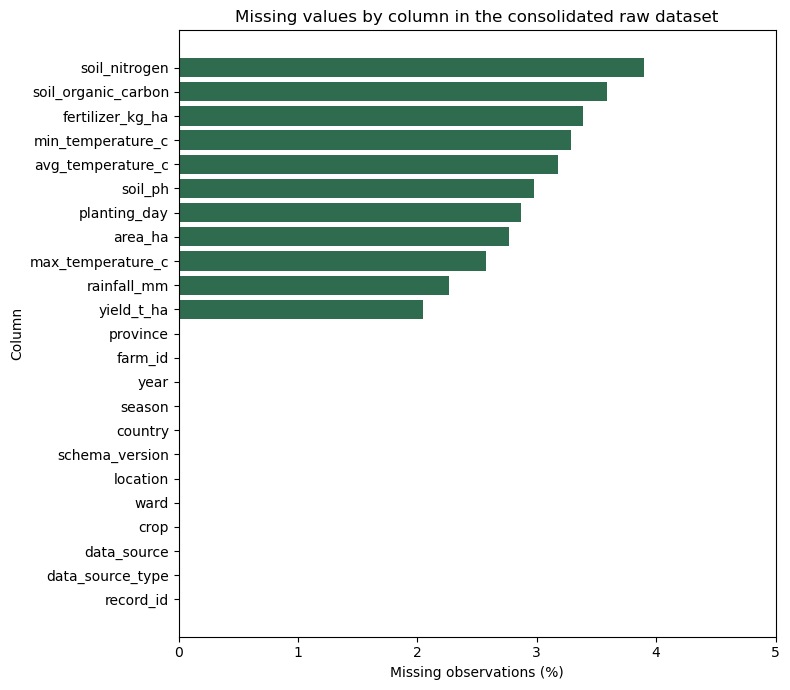

Missing values by column in the consolidated raw SmartCrop dataset. The file is synthetic. Blank cells were injected by the generator and are not survey non-response from Macheke.


In [9]:
figures_dir = DS_ROOT / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

plot_data = missing.sort_values("missing_percent", ascending=True)
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(plot_data["column"], plot_data["missing_percent"], color="#2F6B4F")
ax.set_title("Missing values by column in the consolidated raw dataset")
ax.set_xlabel("Missing observations (%)")
ax.set_ylabel("Column")
ax.set_xlim(0, max(5, float(plot_data["missing_percent"].max()) + 1))
fig.tight_layout()

figure_stem = figures_dir / "01_missing_values"
fig.savefig(figure_stem.with_suffix(".png"), dpi=150)
fig.savefig(figure_stem.with_suffix(".svg"))
fig.savefig(figure_stem.with_suffix(".pdf"))
plt.show()

caption = (
    "Missing values by column in the consolidated raw SmartCrop dataset. "
    "The file is synthetic. Blank cells were injected by the generator and "
    "are not survey non-response from Macheke."
)
figure_stem.with_suffix(".caption.txt").write_text(caption + "\n", encoding="utf-8")
print(caption)


## 8. Interpretation

Read the printed quality report above together with these points:

- A row count equal to the CSV rows plus the Excel rows means both batches were loaded and neither was filtered.
- `data_source_type` should be `SYNTHETIC` for every observation. If a future file introduces `REAL` or `EXTERNAL` measurements, those rows must keep their own label. They must not be silently stacked onto this synthetic file.
- Exact duplicate rows are expected at the generator's duplicate rate. They are copies, including the same `record_id`. Notebook 02 should decide how to drop them. This notebook only counts them.
- Missing values on rainfall, temperature, soil, fertilizer, planting day, area, or yield are expected. Missing values on `record_id`, `crop`, or `data_source_type` would mean the file was damaged.
- Values outside the plausible range are the generator's outliers, or ordinary tail values. Being outside the plausible range does not by itself say which treatment Notebook 02 should use.
- The source catalogue's `not_ingested` status means this pipeline does not yet contain NASA POWER, CHIRPS, SoilGrids, Agritex, or ZIMSTAT measurements. Do not describe the consolidated yield column as official Macheke statistics.

The yield values are an output of a documented formula plus noise. Association between rainfall and yield in this file is therefore partly built in. It is not evidence about Macheke farms.


In [10]:
synthetic_rows = int((consolidated["data_source_type"] == "SYNTHETIC").sum())
other_source_rows = int(len(consolidated) - synthetic_rows)
protected = ["record_id", "farm_id", "crop", "data_source_type", "location"]
protected_missing = int(consolidated[protected].isna().sum().sum())
maize_rows = int((consolidated["crop"] == "maize").sum())

print("Acquisition checks")
print("------------------")
print(f"Consolidated rows: {len(consolidated)}")
print(f"Columns: {consolidated.shape[1]}")
print(f"Synthetic rows: {synthetic_rows}")
print(f"Rows with another source type: {other_source_rows}")
print(f"Maize rows: {maize_rows}")
print(f"Missing values in identity columns {protected}: {protected_missing}")
print(f"Exact duplicate rows: {duplicates['exact_duplicate_rows']}")
print(f"Target column: yield_t_ha")
print(f"Non-missing yield rows: {int(consolidated['yield_t_ha'].notna().sum())}")
print(f"Saved consolidated file: {consolidated_path}")


Acquisition checks
------------------
Consolidated rows: 974
Columns: 23
Synthetic rows: 974
Rows with another source type: 0
Maize rows: 974
Missing values in identity columns ['record_id', 'farm_id', 'crop', 'data_source_type', 'location']: 0
Exact duplicate rows: 14
Target column: yield_t_ha
Non-missing yield rows: 954
Saved consolidated file: /home/marvelous/.dev/Tait/capstone/data-science/data/interim/consolidated_raw.csv


## 9. Conclusion

Notebook 01 loaded a CSV batch, an Excel batch, and an external source catalogue. The two observation batches were coerced to one schema and saved as `data/interim/consolidated_raw.csv`. The catalogue was inspected and left separate because it does not contain measurements.

The consolidated file is labelled synthetic maize data for Macheke, Mashonaland East. It is fit for the next development step, which is cleaning. It is not fit to be quoted as a description of real smallholder yields.

Assumptions that remain in force:

- Ward codes are placeholders.
- Season labels are not a historical weather series.
- Missing values, duplicates, and extreme values were injected so quality checks are observable.
- No real Macheke agricultural extract has been added in this phase.

**Next notebook:** data cleaning, using `consolidated_raw.csv` as the input. Cleaning is not done here.
